# Tostao | EDA de abastecimiento

**Objetivo:** auditar las fuentes y entender la demanda antes de construir variables o entrenar modelos.

**Corte de inventario:** 2024-03-31.  
**Naturaleza de los datos:** desconocida; no se asume que sean reales ni sintéticos.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


DATA_DIR = Path("/content")
FILES = {
    "ventas": "ventas_historicas.csv",
    "inventario": "inventario_actual.csv",
    "catalogo": "catalogo_productos.csv",
    "tiendas": "maestro_tiendas.csv",
    "trends": "ground_truth_trends.csv",
}
INVENTORY_CUTOFF = pd.Timestamp("2024-03-31")

data = {
    name: pd.read_csv(DATA_DIR / filename)
    for name, filename in FILES.items()
}
ventas = data["ventas"].copy()
inventario = data["inventario"].copy()
catalogo = data["catalogo"].copy()
tiendas = data["tiendas"].copy()
trends = data["trends"].copy()

ventas["fecha"] = pd.to_datetime(ventas["fecha"], errors="coerce")
print("Archivos cargados correctamente.")

Archivos cargados correctamente.


## 1. Inventario de archivos, dimensiones y esquema

In [ ]:
file_profile = []
for name, df in data.items():
    file_profile.append({
        "archivo": FILES[name],
        "filas": len(df),
        "columnas": len(df.columns),
        "nombres_columnas": ", ".join(df.columns),
    })
pd.DataFrame(file_profile)

,archivo,filas,columnas,nombres_columnas
0,ventas_historicas.csv,14560,4,"fecha, id_tienda, id_producto, unidades_vendidas"
1,inventario_actual.csv,160,3,"id_tienda, id_producto, stock_actual"
2,catalogo_productos.csv,8,6,"id_producto, nombre, categoria, costo_unitario..."
3,maestro_tiendas.csv,20,3,"id_tienda, ciudad, tamaño_m2"
4,ground_truth_trends.csv,160,3,"id_tienda, id_producto, trend_type"


## 2. Calidad: nulos, duplicados y tipos de datos

In [ ]:
quality_rows = []
for name, df in data.items():
    quality_rows.append({
        "archivo": FILES[name],
        "filas": len(df),
        "duplicados_fila_completa": int(df.duplicated().sum()),
        "celdas_nulas": int(df.isna().sum().sum()),
        "columnas_con_nulos": int((df.isna().sum() > 0).sum()),
    })
quality = pd.DataFrame(quality_rows)
display(quality)

print("\nTipos de datos - ventas")
display(ventas.dtypes.to_frame("dtype"))

,archivo,filas,duplicados_fila_completa,celdas_nulas,columnas_con_nulos
0,ventas_historicas.csv,14560,0,0,0
1,inventario_actual.csv,160,0,0,0
2,catalogo_productos.csv,8,0,0,0
3,maestro_tiendas.csv,20,0,0,0
4,ground_truth_trends.csv,160,0,0,0



Tipos de datos - ventas


,dtype
fecha,datetime64[ns]
id_tienda,object
id_producto,object
unidades_vendidas,int64


## 3. Integridad de llaves y cobertura

In [ ]:
# Llaves duplicadas
print("Duplicados en llave diaria venta:",
      ventas.duplicated(["fecha", "id_tienda", "id_producto"]).sum())
print("Duplicados inventario:",
      inventario.duplicated(["id_tienda", "id_producto"]).sum())
print("Duplicados catálogo:", catalogo["id_producto"].duplicated().sum())
print("Duplicados tiendas:", tiendas["id_tienda"].duplicated().sum())

# Cobertura temporal
print("Periodo:", ventas["fecha"].min(), "a", ventas["fecha"].max())
print("Fechas distintas:", ventas["fecha"].nunique())
print("Tiendas:", ventas["id_tienda"].nunique())
print("Productos:", ventas["id_producto"].nunique())
print("Combinaciones SKU-Tienda:",
      ventas[["id_tienda", "id_producto"]].drop_duplicates().shape[0])

# Comparación de llaves entre fuentes
keys_sales = set(map(tuple, ventas[["id_tienda", "id_producto"]].drop_duplicates().to_numpy()))
keys_stock = set(map(tuple, inventario[["id_tienda", "id_producto"]].drop_duplicates().to_numpy()))
print("Combinaciones venta sin inventario:", len(keys_sales - keys_stock))
print("Combinaciones inventario sin venta:", len(keys_stock - keys_sales))

# Integridad referencial
print("Productos de ventas no encontrados en catálogo:",
      len(set(ventas.id_producto) - set(catalogo.id_producto)))
print("Tiendas de ventas no encontradas en maestro:",
      len(set(ventas.id_tienda) - set(tiendas.id_tienda)))

Duplicados en llave diaria venta: 0
Duplicados inventario: 0
Duplicados catálogo: 0
Duplicados tiendas: 0
Periodo: 2024-01-01 00:00:00 a 2024-03-31 00:00:00
Fechas distintas: 91
Tiendas: 20
Productos: 8
Combinaciones SKU-Tienda: 160
Combinaciones venta sin inventario: 0
Combinaciones inventario sin venta: 0
Productos de ventas no encontrados en catálogo: 0
Tiendas de ventas no encontradas en maestro: 0


## 4. Distribución y anomalías de unidades vendidas

,unidades_vendidas
count,"14,560.00"
mean,13.18
std,7.79
min,0.00
50%,12.00
75%,17.00
90%,24.00
95%,28.00
99%,37.00
max,58.00


Ventas en cero: 26
Ventas negativas: 0
Ventas positivas: 14534


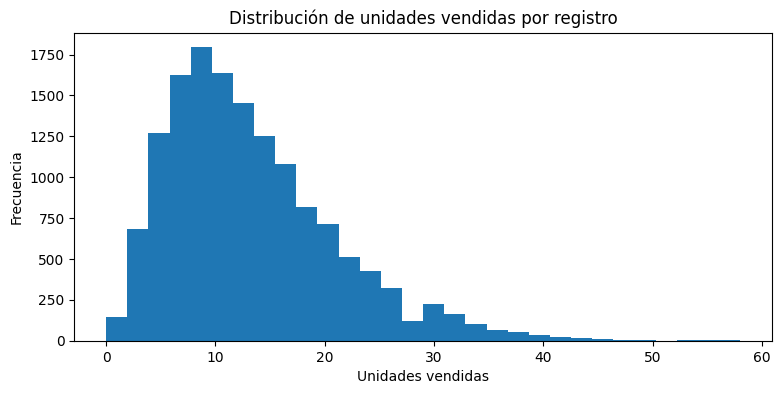

In [ ]:
display(ventas["unidades_vendidas"].describe(
    percentiles=[.50, .75, .90, .95, .99]
).to_frame("unidades_vendidas"))

print("Ventas en cero:", int((ventas.unidades_vendidas == 0).sum()))
print("Ventas negativas:", int((ventas.unidades_vendidas < 0).sum()))
print("Ventas positivas:", int((ventas.unidades_vendidas > 0).sum()))

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(ventas["unidades_vendidas"], bins=30)
ax.set_title("Distribución de unidades vendidas por registro")
ax.set_xlabel("Unidades vendidas")
ax.set_ylabel("Frecuencia")
plt.show()

## 5. Demanda temporal y patrón semanal

,promedio_unidades
dia_semana,
Monday,10.92
Tuesday,10.91
Wednesday,10.69
Thursday,10.81
Friday,16.42
Saturday,16.18
Sunday,16.32


,semana_inicio,unidades,registros,ceros
0,2024-01-01,14385,1120,0
1,2024-01-08,14481,1120,4
2,2024-01-15,14705,1120,2
3,2024-01-22,14624,1120,0
4,2024-01-29,14729,1120,4
5,2024-02-05,14820,1120,4
6,2024-02-12,14860,1120,2
7,2024-02-19,14913,1120,2
8,2024-02-26,14861,1120,0
9,2024-03-04,14713,1120,1


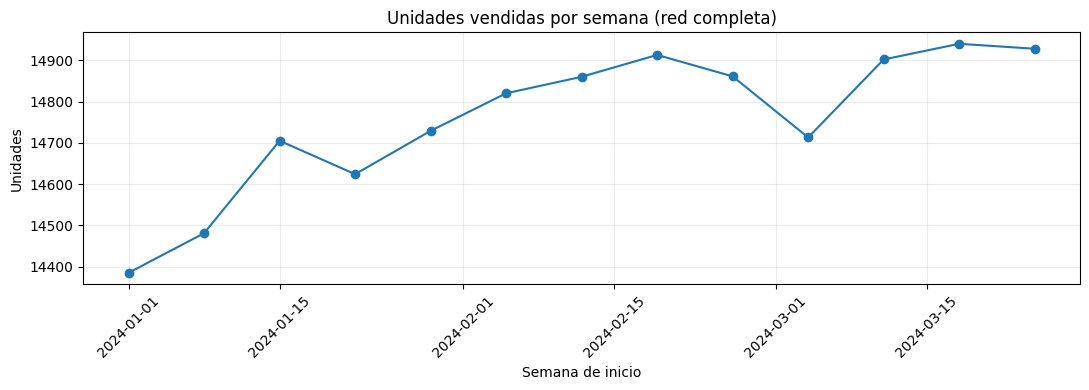

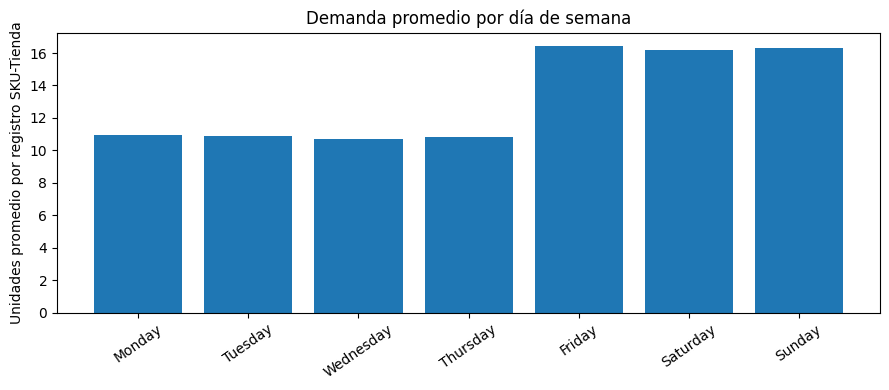

In [ ]:
ventas["dia_semana"] = ventas["fecha"].dt.day_name()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday = (ventas.groupby("dia_semana")["unidades_vendidas"]
           .mean().reindex(weekday_order))
display(weekday.rename("promedio_unidades").to_frame())

ventas["semana_inicio"] = (
    ventas["fecha"] - pd.to_timedelta(ventas["fecha"].dt.weekday, unit="D")
)
weekly = (ventas.groupby("semana_inicio")
          .agg(unidades=("unidades_vendidas", "sum"),
               registros=("unidades_vendidas", "size"),
               ceros=("unidades_vendidas", lambda x: int((x == 0).sum())))
          .reset_index())
display(weekly)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(weekly["semana_inicio"], weekly["unidades"], marker="o")
ax.set_title("Unidades vendidas por semana (red completa)")
ax.set_xlabel("Semana de inicio")
ax.set_ylabel("Unidades")
ax.grid(alpha=.25)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(weekday.index, weekday.values)
ax.set_title("Demanda promedio por día de semana")
ax.set_ylabel("Unidades promedio por registro SKU-Tienda")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

## 6. Demanda por producto, tienda y ciudad

In [ ]:
sku_summary = (ventas.groupby("id_producto")
               .agg(unidades=("unidades_vendidas", "sum"),
                    promedio_diario=("unidades_vendidas", "mean"),
                    desviacion_diaria=("unidades_vendidas", "std"),
                    dias_cero=("unidades_vendidas", lambda x: int((x == 0).sum())))
               .reset_index()
               .merge(catalogo, on="id_producto", how="left"))
sku_summary["margen_unitario"] = sku_summary["precio_venta"] - sku_summary["costo_unitario"]
sku_summary["margen_pct"] = sku_summary["margen_unitario"] / sku_summary["precio_venta"]
display(sku_summary.sort_values("unidades", ascending=False))

store_summary = (ventas.groupby("id_tienda")
                 .agg(unidades=("unidades_vendidas", "sum"),
                      promedio_por_registro=("unidades_vendidas", "mean"))
                 .reset_index()
                 .merge(tiendas, on="id_tienda", how="left"))
display(store_summary.sort_values("unidades", ascending=False))

city_summary = (ventas.merge(tiendas, on="id_tienda", how="left")
                .groupby("ciudad")
                .agg(unidades=("unidades_vendidas", "sum"),
                     tiendas=("id_tienda", "nunique"),
                     promedio_por_registro=("unidades_vendidas", "mean"))
                .reset_index())
display(city_summary)

,id_producto,unidades,promedio_diario,desviacion_diaria,dias_cero,nombre,categoria,costo_unitario,precio_venta,costo_almacenamiento_semanal,margen_unitario,margen_pct
4,PROD_005,32489,17.85,8.48,2,Buñuelo,Alimentos,800,2500,20,1700,0.68
6,PROD_007,31469,17.29,8.46,0,Pastel de Pollo,Alimentos,1500,3500,30,2000,0.57
7,PROD_008,29833,16.39,7.77,0,Jugo de Naranja,Bebidas,2000,5000,50,3000,0.60
5,PROD_006,28895,15.88,7.55,0,Croissant,Alimentos,1200,3500,25,2300,0.66
2,PROD_003,21249,11.68,5.73,1,Cappuccino,Bebidas,1500,4500,15,3000,0.67
1,PROD_002,20580,11.31,5.69,0,Café con Leche,Bebidas,1200,3500,15,2300,0.66
0,PROD_001,14971,8.23,4.39,9,Tinto,Bebidas,800,2500,10,1700,0.68
3,PROD_004,12375,6.80,3.61,14,Pan de Bono,Alimentos,1000,2800,20,1800,0.64


,id_tienda,unidades,promedio_por_registro,ciudad,tamaño_m2
15,STORE_16,14582,20.03,Bogotá,49
7,STORE_08,14252,19.58,Bogotá,49
2,STORE_03,11658,16.01,Bogotá,42
3,STORE_04,11281,15.50,Cali,40
1,STORE_02,10690,14.68,Bogotá,43
11,STORE_12,10367,14.24,Medellín,35
18,STORE_19,10360,14.23,Bogotá,37
4,STORE_05,10248,14.08,Bogotá,34
17,STORE_18,10033,13.78,Bogotá,38
13,STORE_14,9918,13.62,Bogotá,34


,ciudad,unidades,tiendas,promedio_por_registro
0,Bogotá,140080,14,13.74
1,Cali,11281,1,15.50
2,Medellín,40500,5,11.13


## 7. Variabilidad por combinación SKU-Tienda

In [ ]:
combo = (ventas.groupby(["id_tienda", "id_producto"])
         .agg(dias_observados=("fecha", "nunique"),
              demanda_total=("unidades_vendidas", "sum"),
              media_diaria=("unidades_vendidas", "mean"),
              std_diaria=("unidades_vendidas", "std"),
              dias_cero=("unidades_vendidas", lambda x: int((x == 0).sum())))
         .reset_index())
combo["cv_diario"] = combo["std_diaria"] / combo["media_diaria"].replace(0, np.nan)
display(combo["cv_diario"].describe().to_frame("CV diario"))
display(combo.sort_values("cv_diario", ascending=False).head(25))

,CV diario
count,160.00
mean,0.41
std,0.07
min,0.26
25%,0.37
50%,0.41
75%,0.46
max,0.66


,id_tienda,id_producto,dias_observados,demanda_total,media_diaria,std_diaria,dias_cero,cv_diario
131,STORE_17,PROD_004,91,263,2.89,1.90,7,0.66
130,STORE_17,PROD_003,91,517,5.68,3.27,0,0.58
51,STORE_07,PROD_004,91,322,3.54,2.02,0,0.57
128,STORE_17,PROD_001,91,429,4.71,2.58,3,0.55
55,STORE_07,PROD_008,91,677,7.44,4.06,0,0.55
66,STORE_09,PROD_003,91,771,8.47,4.45,0,0.52
48,STORE_07,PROD_001,91,349,3.84,2.01,4,0.52
155,STORE_20,PROD_004,91,572,6.29,3.30,1,0.52
32,STORE_05,PROD_001,91,770,8.46,4.43,0,0.52
3,STORE_01,PROD_004,91,564,6.20,3.21,1,0.52


## 8. Inventario y cobertura descriptiva

In [ ]:
stock_check = inventario.merge(
    ventas.groupby(["id_tienda", "id_producto"])["unidades_vendidas"]
          .mean().rename("demanda_diaria_media").reset_index(),
    on=["id_tienda", "id_producto"], how="left"
)
stock_check["cobertura_dias_teorica"] = (
    stock_check["stock_actual"] /
    stock_check["demanda_diaria_media"].replace(0, np.nan)
)
display(stock_check["stock_actual"].describe().to_frame("stock_actual"))
display(stock_check["cobertura_dias_teorica"].describe(
    percentiles=[.10, .25, .50, .75, .90]
).to_frame("cobertura_dias_teorica"))
print("Combinaciones con stock cero:", int((stock_check.stock_actual == 0).sum()))
print("Cobertura < 1 día:", int((stock_check.cobertura_dias_teorica < 1).sum()))
print("Cobertura < 3 días:", int((stock_check.cobertura_dias_teorica < 3).sum()))

coverage_by_sku = (stock_check.groupby("id_producto")["cobertura_dias_teorica"]
                   .median().rename("cobertura_mediana_dias").reset_index())
display(coverage_by_sku.merge(catalogo[["id_producto", "nombre"]], on="id_producto"))

,stock_actual
count,160.00
mean,21.04
std,17.42
min,0.00
25%,8.00
50%,17.50
75%,31.00
max,97.00


,cobertura_dias_teorica
count,160.00
mean,1.98
std,2.17
min,0.00
10%,0.20
25%,0.60
50%,1.38
75%,2.47
90%,4.49
max,15.54


Combinaciones con stock cero: 5
Cobertura < 1 día: 61
Cobertura < 3 días: 128


,id_producto,cobertura_mediana_dias,nombre
0,PROD_001,1.93,Tinto
1,PROD_002,1.26,Café con Leche
2,PROD_003,1.70,Cappuccino
3,PROD_004,3.14,Pan de Bono
4,PROD_005,0.82,Buñuelo
5,PROD_006,1.18,Croissant
6,PROD_007,0.63,Pastel de Pollo
7,PROD_008,1.16,Jugo de Naranja


## 9. Archivo auxiliar ground_truth_trends.csv

In [ ]:
trends

,id_tienda,id_producto,trend_type
0,STORE_01,PROD_001,up
1,STORE_01,PROD_002,random
2,STORE_01,PROD_003,seasonal
3,STORE_01,PROD_004,up
4,STORE_01,PROD_005,down
...,...,...,...
155,STORE_20,PROD_004,random
156,STORE_20,PROD_005,seasonal
157,STORE_20,PROD_006,up
158,STORE_20,PROD_007,random


In [ ]:
# Solo auditoría de contenido y cobertura.
display(trends["trend_type"].value_counts(dropna=False).to_frame("combinaciones"))
print("Llaves duplicadas:", trends.duplicated(["id_tienda", "id_producto"]).sum())
trend_keys = set(map(tuple, trends[["id_tienda", "id_producto"]].drop_duplicates().to_numpy()))
print("Combinaciones en ventas sin etiqueta:", len(keys_sales - trend_keys))
print("Etiquetas sin combinación en ventas:", len(trend_keys - keys_sales))
print("\nNo utilizar trend_type como predictor hasta documentar quién lo generó, cuándo y con qué información.")

,combinaciones
trend_type,
seasonal,57
down,44
random,32
up,27


Llaves duplicadas: 0
Combinaciones en ventas sin etiqueta: 0
Etiquetas sin combinación en ventas: 0

No utilizar trend_type como predictor hasta documentar quién lo generó, cuándo y con qué información.


In [ ]:

# ============================================================
# TOSTAO | SUPPLY CHAIN ANALYTICS - EDA VISUAL
# Dashboard interactivo con Plotly
# ============================================================

!pip -q install plotly ipywidgets

import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, HTML

# ------------------------------------------------------------
# 1. PREPARACIÓN DE DATOS
# ------------------------------------------------------------

ventas_viz = ventas.copy()
stock_viz = inventario.copy()
catalogo_viz = catalogo.copy()
tiendas_viz = tiendas.copy()

ventas_viz["fecha"] = pd.to_datetime(ventas_viz["fecha"])

ventas_viz = ventas_viz.merge(
    catalogo_viz[["id_producto", "nombre", "precio_venta",
                  "costo_unitario", "costo_almacenamiento_semanal"]],
    on="id_producto", how="left"
)

ventas_viz = ventas_viz.merge(
    tiendas_viz[["id_tienda", "ciudad", "tamaño_m2"]],
    on="id_tienda", how="left"
)

ventas_viz["margen_unitario"] = (
    ventas_viz["precio_venta"] - ventas_viz["costo_unitario"]
)

ventas_viz["venta_valor"] = (
    ventas_viz["unidades_vendidas"] * ventas_viz["precio_venta"]
)

ventas_viz["margen_estimado"] = (
    ventas_viz["unidades_vendidas"] * ventas_viz["margen_unitario"]
)

ventas_viz["dia_semana"] = ventas_viz["fecha"].dt.day_name()

ventas_viz["semana"] = (
    ventas_viz["fecha"]
    - pd.to_timedelta(ventas_viz["fecha"].dt.weekday, unit="D")
)

# Agregación semanal
semanal = (
    ventas_viz.groupby(
        ["semana", "id_tienda", "id_producto", "nombre"],
        as_index=False
    )
    .agg(
        demanda=("unidades_vendidas", "sum"),
        venta=("venta_valor", "sum"),
        margen=("margen_estimado", "sum")
    )
)

# Inventario y cobertura
cobertura = stock_viz.merge(
    ventas_viz.groupby(
        ["id_tienda", "id_producto"]
    )["unidades_vendidas"].mean().reset_index(
        name="demanda_diaria"
    ),
    on=["id_tienda", "id_producto"],
    how="left"
)

cobertura["cobertura_dias"] = (
    cobertura["stock_actual"] /
    cobertura["demanda_diaria"].replace(0, np.nan)
)

# ------------------------------------------------------------
# 2. INDICADORES GENERALES
# ------------------------------------------------------------

total_unidades = ventas_viz["unidades_vendidas"].sum()
total_ventas = ventas_viz["venta_valor"].sum()
total_margen = ventas_viz["margen_estimado"].sum()
total_stock = stock_viz["stock_actual"].sum()

display(HTML("""
<h1 style='color:#6B4226'>TOSTAO | SUPPLY CHAIN ANALYTICS</h1>
<h3>Exploratory Data Analysis - Dashboard</h3>
<p>Demanda · Inventario · Rentabilidad · Comportamiento comercial</p>
"""))

fig = go.Figure()

kpis = [
    ("Unidades vendidas", f"{total_unidades:,.0f}"),
    ("Ventas estimadas", f"${total_ventas:,.0f}"),
    ("Margen estimado", f"${total_margen:,.0f}"),
    ("Inventario actual", f"{total_stock:,.0f}")
]

for i, (label, value) in enumerate(kpis):
    fig.add_trace(go.Indicator(
        mode="number",
        value=[total_unidades, total_ventas,
               total_margen, total_stock][i],
        title={"text": label},
        domain={"row": 0, "column": i},
        number={"valueformat": ",.0f"}
    ))

fig.update_layout(
    grid={"rows": 1, "columns": 4, "pattern": "independent"},
    height=180,
    template="plotly_white",
    title="Indicadores generales"
)

fig.show()

# ------------------------------------------------------------
# 3. EVOLUCIÓN SEMANAL
# ------------------------------------------------------------

demanda_semanal = (
    semanal.groupby("semana", as_index=False)
    .agg(demanda=("demanda", "sum"))
)

fig = px.line(
    demanda_semanal,
    x="semana",
    y="demanda",
    markers=True,
    title="Evolución semanal de la demanda",
    labels={
        "semana": "Semana",
        "demanda": "Unidades vendidas"
    }
)

fig.update_layout(template="plotly_white")
fig.show()

# ------------------------------------------------------------
# 4. COMPORTAMIENTO POR DÍA DE SEMANA
# ------------------------------------------------------------

orden_dias = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

demanda_dia = (
    ventas_viz.groupby("dia_semana")["unidades_vendidas"]
    .mean()
    .reindex(orden_dias)
    .reset_index()
)

fig = px.bar(
    demanda_dia,
    x="dia_semana",
    y="unidades_vendidas",
    title="Demanda promedio por día de semana",
    labels={
        "dia_semana": "Día",
        "unidades_vendidas": "Unidades promedio"
    }
)

fig.update_layout(template="plotly_white")
fig.show()

# ------------------------------------------------------------
# 5. DEMANDA POR PRODUCTO
# ------------------------------------------------------------

producto = (
    ventas_viz.groupby("nombre", as_index=False)
    .agg(
        unidades=("unidades_vendidas", "sum"),
        margen=("margen_estimado", "sum")
    )
    .sort_values("unidades", ascending=False)
)

fig = px.bar(
    producto,
    x="nombre",
    y="unidades",
    color="margen",
    title="Demanda acumulada por producto",
    color_continuous_scale="Teal",
    labels={
        "nombre": "Producto",
        "unidades": "Unidades vendidas",
        "margen": "Margen estimado"
    }
)

fig.update_layout(template="plotly_white")
fig.show()

# ------------------------------------------------------------
# 6. COMPORTAMIENTO POR CIUDAD
# ------------------------------------------------------------

ciudad = (
    ventas_viz.groupby("ciudad", as_index=False)
    .agg(
        unidades=("unidades_vendidas", "sum"),
        ventas=("venta_valor", "sum"),
        margen=("margen_estimado", "sum")
    )
)

fig = px.bar(
    ciudad,
    x="ciudad",
    y="unidades",
    color="ciudad",
    title="Demanda por ciudad",
    labels={"unidades": "Unidades vendidas"}
)

fig.update_layout(template="plotly_white")
fig.show()

# ------------------------------------------------------------
# 7. DISPERSIÓN Y VARIABILIDAD SKU-TIENDA
# ------------------------------------------------------------

variabilidad = (
    ventas_viz.groupby(
        ["id_tienda", "id_producto"]
    )
    .agg(
        media=("unidades_vendidas", "mean"),
        desviacion=("unidades_vendidas", "std"),
        demanda=("unidades_vendidas", "sum")
    )
    .reset_index()
)

variabilidad["CV"] = (
    variabilidad["desviacion"] /
    variabilidad["media"].replace(0, np.nan)
)

fig = px.scatter(
    variabilidad,
    x="media",
    y="desviacion",
    size="demanda",
    color="CV",
    hover_data=["id_tienda", "id_producto"],
    title="Variabilidad de la demanda por SKU-Tienda",
    color_continuous_scale="Viridis",
    labels={
        "media": "Demanda diaria promedio",
        "desviacion": "Desviación estándar",
        "CV": "Coeficiente de variación"
    }
)

fig.update_layout(template="plotly_white")
fig.show()

# ------------------------------------------------------------
# 8. MATRIZ DE DEMANDA PRODUCTO-TIENDA
# ------------------------------------------------------------

heatmap = ventas_viz.pivot_table(
    index="id_producto",
    columns="id_tienda",
    values="unidades_vendidas",
    aggfunc="mean"
)

fig = px.imshow(
    heatmap,
    aspect="auto",
    color_continuous_scale="YlOrRd",
    title="Mapa de calor: demanda diaria promedio SKU-Tienda",
    labels={
        "x": "Tienda",
        "y": "Producto",
        "color": "Unidades promedio"
    }
)

fig.update_layout(template="plotly_white")
fig.show()

# ------------------------------------------------------------
# 9. COBERTURA DE INVENTARIO
# ------------------------------------------------------------

fig = px.histogram(
    cobertura.dropna(subset=["cobertura_dias"]),
    x="cobertura_dias",
    nbins=25,
    title="Distribución de cobertura de inventario",
    labels={"cobertura_dias": "Días de cobertura"}
)

fig.add_vline(
    x=1,
    line_dash="dash",
    annotation_text="1 día"
)

fig.add_vline(
    x=3,
    line_dash="dash",
    annotation_text="3 días"
)

fig.update_layout(template="plotly_white")
fig.show()

# ------------------------------------------------------------
# 10. TAMAÑO DE TIENDA VS DEMANDA
# ------------------------------------------------------------

tienda_scatter = (
    ventas_viz.groupby(
        ["id_tienda", "ciudad", "tamaño_m2"],
        as_index=False
    )
    .agg(unidades=("unidades_vendidas", "sum"))
)

fig = px.scatter(
    tienda_scatter,
    x="tamaño_m2",
    y="unidades",
    color="ciudad",
    size="unidades",
    hover_name="id_tienda",
    trendline="ols",
    title="Relación entre tamaño de tienda y demanda",
    labels={
        "tamaño_m2": "Tamaño (m²)",
        "unidades": "Unidades vendidas"
    }
)

fig.update_layout(template="plotly_white")
fig.show()

# ------------------------------------------------------------
# 11. TABLA DE PRIORIZACIÓN DE INVENTARIO
# ------------------------------------------------------------

priorizacion = (
    cobertura.merge(
        catalogo_viz[["id_producto", "nombre"]],
        on="id_producto",
        how="left"
    )
)

priorizacion["nivel_cobertura"] = np.select(
    [
        priorizacion["cobertura_dias"] < 1,
        priorizacion["cobertura_dias"] < 3
    ],
    ["Crítica", "Baja"],
    default="Mayor o igual a 3 días"
)

display(
    priorizacion.sort_values("cobertura_dias")[
        [
            "id_tienda",
            "nombre",
            "stock_actual",
            "demanda_diaria",
            "cobertura_dias",
            "nivel_cobertura"
        ]
    ].head(30)
)

print("Dashboard EDA finalizado.")



,id_tienda,nombre,stock_actual,demanda_diaria,cobertura_dias,nivel_cobertura
52,STORE_07,Buñuelo,0,6.23,0.00,Crítica
58,STORE_08,Cappuccino,0,17.48,0.00,Crítica
81,STORE_11,Café con Leche,0,12.93,0.00,Crítica
128,STORE_17,Tinto,0,4.71,0.00,Crítica
150,STORE_19,Pastel de Pollo,0,18.04,0.00,Crítica
94,STORE_12,Pastel de Pollo,1,18.67,0.05,Crítica
36,STORE_05,Buñuelo,1,17.65,0.06,Crítica
57,STORE_08,Café con Leche,1,16.30,0.06,Crítica
92,STORE_12,Buñuelo,2,18.23,0.11,Crítica
125,STORE_16,Croissant,3,25.51,0.12,Crítica


Dashboard EDA finalizado.


In [ ]:
data_completa = ventas.merge(
    catalogo_viz[["id_producto", "nombre", "precio_venta",
                  "costo_unitario", "costo_almacenamiento_semanal"]],
    on="id_producto", how="left"
)

data_completa = data_completa.merge(
    tiendas[["id_tienda", "ciudad", "tamaño_m2"]],
    on="id_tienda", how="left"
)


In [ ]:
data_completa

,fecha,id_tienda,id_producto,unidades_vendidas,dia_semana,semana_inicio,nombre,precio_venta,costo_unitario,costo_almacenamiento_semanal,ciudad,tamaño_m2
0,2024-01-01,STORE_01,PROD_001,5,Monday,2024-01-01,Tinto,2500,800,10,Bogotá,28
1,2024-01-02,STORE_01,PROD_001,4,Tuesday,2024-01-01,Tinto,2500,800,10,Bogotá,28
2,2024-01-03,STORE_01,PROD_001,3,Wednesday,2024-01-01,Tinto,2500,800,10,Bogotá,28
3,2024-01-04,STORE_01,PROD_001,4,Thursday,2024-01-01,Tinto,2500,800,10,Bogotá,28
4,2024-01-05,STORE_01,PROD_001,10,Friday,2024-01-01,Tinto,2500,800,10,Bogotá,28
...,...,...,...,...,...,...,...,...,...,...,...,...
14555,2024-03-27,STORE_20,PROD_008,17,Wednesday,2024-03-25,Jugo de Naranja,5000,2000,50,Medellín,33
14556,2024-03-28,STORE_20,PROD_008,7,Thursday,2024-03-25,Jugo de Naranja,5000,2000,50,Medellín,33
14557,2024-03-29,STORE_20,PROD_008,31,Friday,2024-03-25,Jugo de Naranja,5000,2000,50,Medellín,33
14558,2024-03-30,STORE_20,PROD_008,21,Saturday,2024-03-25,Jugo de Naranja,5000,2000,50,Medellín,33


In [ ]:
# Instalamos la librería (si no está)
!pip install -q ydata-profiling

from ydata_profiling import ProfileReport

profile = ProfileReport(
    data_completa,
    title="Reporte Exploratorio - Segmentación",
    explorative=True
)

profile.to_file("/content/reporte_segmentacion.html")
print("✅ Reporte generado: /content/reporte_segmentacion.html")

/tmp/ipykernel_1153/3577145403.py:4: DeprecationWarning:


    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    



Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 12/12 [00:00<00:00, 29.97it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Reporte generado: /content/reporte_segmentacion.html
